# 05. RFM Customer Segmentation Analysis

This notebook performs **Recency, Frequency, and Monetary (RFM)** segmentation on our e-commerce transaction data. 

The goal is to categorize customers into distinct behavioral segments based on:
- **Recency (R):** How recently did the customer make a purchase?
- **Frequency (F):** How many distinct orders did they place?
- **Monetary (M):** How much total revenue did they generate?

These segments help marketing and retention teams identify who our best customers are, who is at risk of churning, and who needs a re-engagement nudge.


### Step 1: Import Required Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt
import warnings

warnings.filterwarnings('ignore')


### Step 2: Configure Chart Styling

In [2]:
plt.style.use('default')
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 10


### Step 3: Load Clean Transaction Dataset

In [3]:
df = pd.read_csv('data/retail_cleaned.csv')
print(f'Total rows loaded: {len(df):,}')


Total rows loaded: 779,425


### Step 4: Preview First 5 Rows and Data Types

In [4]:
df.head()


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country,TotalRevenue,InvoiceMonth
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,83.4,2009-12
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0,2009-12
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0,2009-12
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,100.8,2009-12
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,30.0,2009-12


### Step 5: Convert InvoiceDate to Datetime

In [5]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
print(f'Earliest invoice: {df["InvoiceDate"].min()}')
print(f'Latest invoice  : {df["InvoiceDate"].max()}')


Earliest invoice: 2009-12-01 07:45:00
Latest invoice  : 2011-12-09 12:50:00


### Step 6: Define Analysis Reference Date
We set our snapshot date to one day after the most recent transaction.

In [6]:
snapshot_date = df['InvoiceDate'].max() + dt.timedelta(days=1)
print(f'Snapshot reference date: {snapshot_date.date()}')


Snapshot reference date: 2011-12-10


### Step 7: Calculate Recency (Days Since Last Order)

In [7]:
recency_df = df.groupby('CustomerID')['InvoiceDate'].max().reset_index()
recency_df['Recency'] = (snapshot_date - recency_df['InvoiceDate']).dt.days
recency_df = recency_df[['CustomerID', 'Recency']]
recency_df.head()


,CustomerID,Recency
0,12346,326
1,12347,2
2,12348,75
3,12349,19
4,12350,310


### Step 8: Calculate Frequency (Total Unique Invoices)

In [8]:
frequency_df = df.groupby('CustomerID')['Invoice'].nunique().reset_index()
frequency_df.columns = ['CustomerID', 'Frequency']
frequency_df.head()


,CustomerID,Frequency
0,12346,12
1,12347,8
2,12348,5
3,12349,4
4,12350,1


### Step 9: Calculate Monetary Value (Total Spend)

In [9]:
monetary_df = df.groupby('CustomerID')['TotalRevenue'].sum().reset_index()
monetary_df.columns = ['CustomerID', 'Monetary']
monetary_df['Monetary'] = monetary_df['Monetary'].round(2)
monetary_df.head()


,CustomerID,Monetary
0,12346,77556.46
1,12347,4921.53
2,12348,2019.40
3,12349,4428.69
4,12350,334.40


### Step 10: Merge Recency, Frequency, and Monetary Metrics

In [10]:
rfm = recency_df.merge(frequency_df, on='CustomerID').merge(monetary_df, on='CustomerID')
print(f'Total customers calculated: {len(rfm):,}')
rfm.head()


Total customers calculated: 5,878


,CustomerID,Recency,Frequency,Monetary
0,12346,326,12,77556.46
1,12347,2,8,4921.53
2,12348,75,5,2019.40
3,12349,19,4,4428.69
4,12350,310,1,334.40


### Step 11: Summary Statistics for RFM Values

In [11]:
rfm[['Recency', 'Frequency', 'Monetary']].describe().round(2)


,Recency,Frequency,Monetary
count,5878.00,5878.00,5878.00
mean,201.33,6.29,2955.90
std,209.34,13.01,14440.85
min,1.00,1.00,2.95
25%,26.00,1.00,342.28
50%,96.00,3.00,867.74
75%,380.00,7.00,2248.30
max,739.00,398.00,580987.04


### Step 12: Check Distributions of R, F, and M

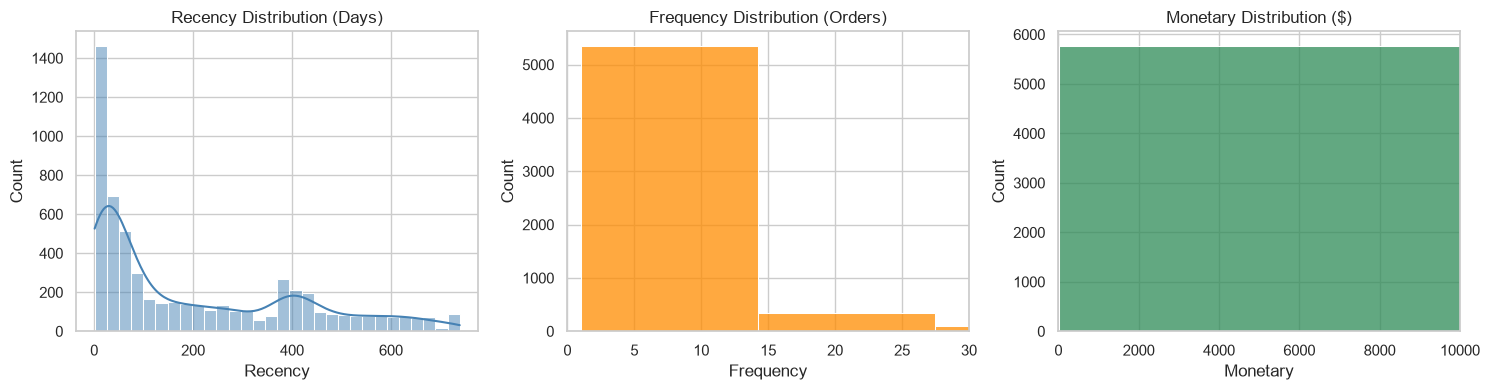

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(rfm['Recency'], bins=30, ax=axes[0], color='steelblue', kde=True)
axes[0].set_title('Recency Distribution (Days)')

sns.histplot(rfm['Frequency'], bins=30, ax=axes[1], color='darkorange', kde=False)
axes[1].set_title('Frequency Distribution (Orders)')
axes[1].set_xlim(0, 30)

sns.histplot(rfm['Monetary'], bins=30, ax=axes[2], color='seagreen', kde=False)
axes[2].set_title('Monetary Distribution ($)')
axes[2].set_xlim(0, 10000)

plt.tight_layout()
plt.show()


### Step 13: Assign Recency Score (R_Score 1–5)
Higher score is given to more recent buyers (lower days).

In [13]:
rfm['R_Score'] = pd.qcut(rfm['Recency'], q=5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm[['CustomerID', 'Recency', 'R_Score']].head()


,CustomerID,Recency,R_Score
0,12346,326,2
1,12347,2,5
2,12348,75,3
3,12349,19,5
4,12350,310,2


### Step 14: Assign Frequency Score (F_Score 1–5)
Using rank method to handle ties cleanly across order counts.

In [14]:
rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method='first'), q=5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm[['CustomerID', 'Frequency', 'F_Score']].head()


,CustomerID,Frequency,F_Score
0,12346,12,5
1,12347,8,4
2,12348,5,4
3,12349,4,3
4,12350,1,1


### Step 15: Assign Monetary Score (M_Score 1–5)
Higher score is given to higher total spend.

In [15]:
rfm['M_Score'] = pd.qcut(rfm['Monetary'], q=5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm[['CustomerID', 'Monetary', 'M_Score']].head()


,CustomerID,Monetary,M_Score
0,12346,77556.46,5
1,12347,4921.53,5
2,12348,2019.40,4
3,12349,4428.69,5
4,12350,334.40,2


### Step 16: Verify Score Distributions Across Quintiles

In [16]:
score_counts = pd.DataFrame({
    'R_Score': rfm['R_Score'].value_counts().sort_index(),
    'F_Score': rfm['F_Score'].value_counts().sort_index(),
    'M_Score': rfm['M_Score'].value_counts().sort_index()
})
score_counts


,R_Score,F_Score,M_Score
1,1175,1176,1176
2,1172,1175,1175
3,1167,1176,1176
4,1176,1175,1175
5,1188,1176,1176


### Step 17: Combine Scores into Composite RFM Score

In [17]:
rfm['RFM_Code'] = rfm['R_Score'].astype(str) + rfm['F_Score'].astype(str) + rfm['M_Score'].astype(str)
rfm['RFM_Avg'] = ((rfm['R_Score'] + rfm['F_Score'] + rfm['M_Score']) / 3.0).round(2)
rfm.head()


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Code,RFM_Avg
0,12346,326,12,77556.46,2,5,5,255,4.00
1,12347,2,8,4921.53,5,4,5,545,4.67
2,12348,75,5,2019.40,3,4,4,344,3.67
3,12349,19,4,4428.69,5,3,5,535,4.33
4,12350,310,1,334.40,2,1,2,212,1.67


### Step 18: Define Customer Segment Mapping Function

In [18]:
def map_rfm_segment(row):
    r, f, m = row['R_Score'], row['F_Score'], row['M_Score']
    if r >= 4 and f >= 4 and m >= 4:
        return 'Champions'
    elif r >= 3 and f >= 3:
        return 'Loyal Customers'
    elif r >= 4 and f < 2:
        return 'Recent New Customers'
    elif r <= 2 and f >= 3:
        return 'At Risk / High Value Churn'
    elif r <= 2 and f <= 2:
        return 'Hibernating / Churned'
    else:
        return 'Potential Loyalists'


### Step 19: Apply Segment Mapping to All Customers

In [19]:
rfm['Segment'] = rfm.apply(map_rfm_segment, axis=1)
rfm['Segment'].value_counts()


Segment
Hibernating / Churned         1523
Loyal Customers               1406
Champions                     1297
At Risk / High Value Churn     824
Potential Loyalists            660
Recent New Customers           168
Name: count, dtype: int64

### Step 20: Calculate Aggregate Metrics by Segment

In [20]:
segment_kpis = rfm.groupby('Segment').agg(
    Customer_Count=('CustomerID', 'count'),
    Avg_Recency=('Recency', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Spend=('Monetary', 'mean'),
    Total_Revenue=('Monetary', 'sum')
).reset_index()

segment_kpis['Avg_Recency'] = segment_kpis['Avg_Recency'].round(1)
segment_kpis['Avg_Frequency'] = segment_kpis['Avg_Frequency'].round(1)
segment_kpis['Avg_Spend'] = segment_kpis['Avg_Spend'].round(2)
segment_kpis['Total_Revenue'] = segment_kpis['Total_Revenue'].round(2)
segment_kpis


,Segment,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Spend,Total_Revenue
0,At Risk / High Value Churn,824,369.1,4.9,1928.86,1589384.31
1,Champions,1297,20.0,17.1,9143.86,11859591.49
2,Hibernating / Churned,1523,459.3,1.3,429.70,654426.70
3,Loyal Customers,1406,71.3,5.4,1902.41,2674784.99
4,Potential Loyalists,660,73.8,1.5,819.58,540923.14
5,Recent New Customers,168,29.7,1.0,331.51,55693.62


### Step 21: Calculate Customer Volume and Revenue Shares

In [21]:
total_customers = segment_kpis['Customer_Count'].sum()
total_revenue = segment_kpis['Total_Revenue'].sum()

segment_kpis['Customer_Share_%'] = (segment_kpis['Customer_Count'] * 100 / total_customers).round(2)
segment_kpis['Revenue_Share_%'] = (segment_kpis['Total_Revenue'] * 100 / total_revenue).round(2)
segment_kpis = segment_kpis.sort_values(by='Total_Revenue', ascending=False).reset_index(drop=True)
segment_kpis


,Segment,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Spend,Total_Revenue,Customer_Share_%,Revenue_Share_%
0,Champions,1297,20.0,17.1,9143.86,11859591.49,22.07,68.26
1,Loyal Customers,1406,71.3,5.4,1902.41,2674784.99,23.92,15.39
2,At Risk / High Value Churn,824,369.1,4.9,1928.86,1589384.31,14.02,9.15
3,Hibernating / Churned,1523,459.3,1.3,429.70,654426.70,25.91,3.77
4,Potential Loyalists,660,73.8,1.5,819.58,540923.14,11.23,3.11
5,Recent New Customers,168,29.7,1.0,331.51,55693.62,2.86,0.32


### Step 22: Visualize Customer Volume by Segment

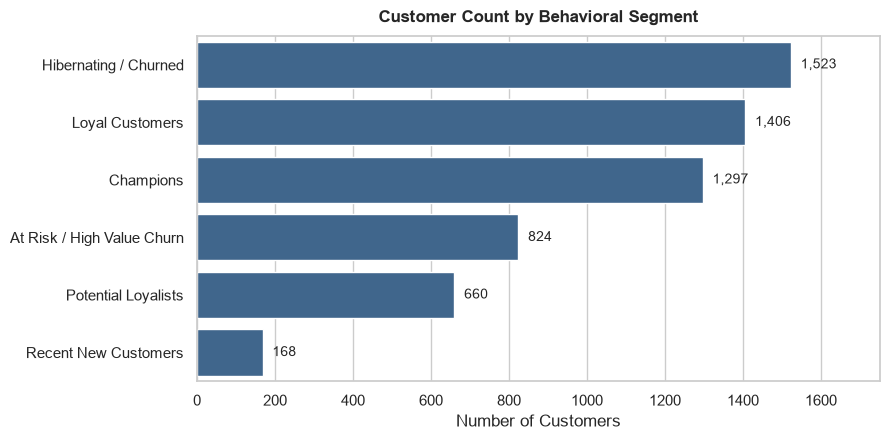

In [22]:
plt.figure(figsize=(9, 4.5))
bar_cust = sns.barplot(
    data=segment_kpis.sort_values(by='Customer_Count', ascending=False),
    x='Customer_Count',
    y='Segment',
    color='#336699'
)
plt.title('Customer Count by Behavioral Segment', fontsize=12, fontweight='bold', pad=10)
plt.xlabel('Number of Customers')
plt.ylabel('')

for p in bar_cust.patches:
    width = p.get_width()
    plt.text(width + 25, p.get_y() + p.get_height() / 2, f'{int(width):,}', va='center')

plt.xlim(0, segment_kpis['Customer_Count'].max() * 1.15)
plt.tight_layout()
plt.show()


### Step 23: Visualize Total Revenue by Segment

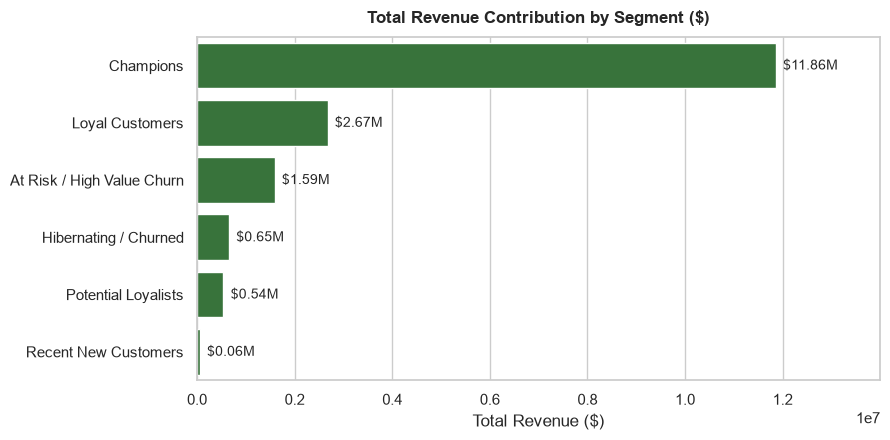

In [23]:
plt.figure(figsize=(9, 4.5))
bar_rev = sns.barplot(
    data=segment_kpis,
    x='Total_Revenue',
    y='Segment',
    color='#2E7D32'
)
plt.title('Total Revenue Contribution by Segment ($)', fontsize=12, fontweight='bold', pad=10)
plt.xlabel('Total Revenue ($)')
plt.ylabel('')

for p in bar_rev.patches:
    width = p.get_width()
    plt.text(width + 150000, p.get_y() + p.get_height() / 2, f'${width/1e6:.2f}M', va='center')

plt.xlim(0, segment_kpis['Total_Revenue'].max() * 1.18)
plt.tight_layout()
plt.show()


### Step 24: Scatter Plot of Recency vs. Monetary Spend

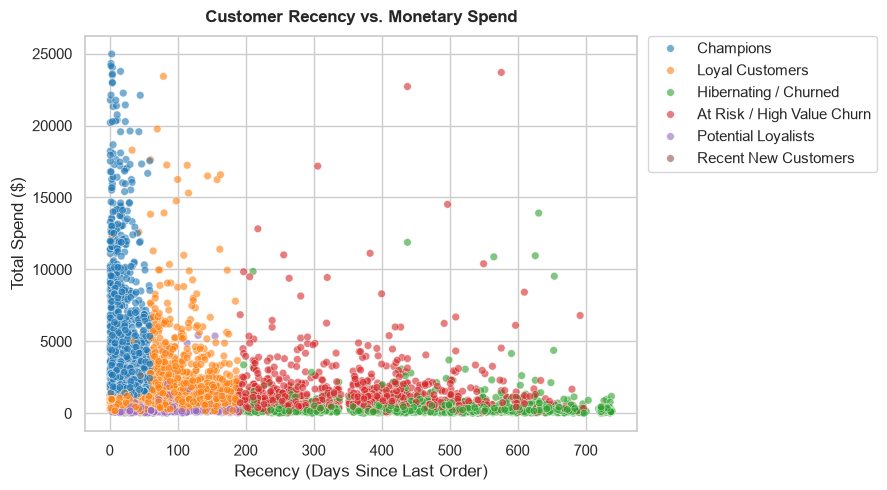

In [24]:
plt.figure(figsize=(9, 5))
sample_rfm = rfm[rfm['Monetary'] <= 25000]

sns.scatterplot(
    data=sample_rfm,
    x='Recency',
    y='Monetary',
    hue='Segment',
    alpha=0.6,
    palette='tab10',
    s=30
)
plt.title('Customer Recency vs. Monetary Spend', fontsize=12, fontweight='bold', pad=10)
plt.xlabel('Recency (Days Since Last Order)')
plt.ylabel('Total Spend ($)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)
plt.tight_layout()
plt.show()


### Step 25: Save Clean RFM Segments Dataset

In [25]:
output_path = 'data/rfm_customer_segments.csv'
rfm.to_csv(output_path, index=False)
print(f'Successfully saved {len(rfm):,} records to {output_path}')


Successfully saved 5,878 records to data/rfm_customer_segments.csv
